# Bookstore sales analysis

Analysis of the `bookstore` PostgreSQL database: 2,000 books, 5,000 orders and about 10,000 order lines 

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.bookstore.analysis import query_df, read_query
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

millions = FuncFormatter(lambda value, _: f"{value / 1e6:,.0f}M")

## 1. Dataset overview

In [2]:
overview = query_df("""
    SELECT 'publishers' AS table_name, COUNT(*) AS row_count FROM publishers
    UNION ALL SELECT 'authors',         COUNT(*) FROM authors
    UNION ALL SELECT 'categories',      COUNT(*) FROM categories
    UNION ALL SELECT 'books',           COUNT(*) FROM books
    UNION ALL SELECT 'author_books',    COUNT(*) FROM author_books
    UNION ALL SELECT 'book_categories', COUNT(*) FROM book_categories
    UNION ALL SELECT 'customers',       COUNT(*) FROM customers
    UNION ALL SELECT 'orders',          COUNT(*) FROM orders
    UNION ALL SELECT 'order_items',     COUNT(*) FROM order_items
""")
overview

,table_name,row_count
0,publishers,50
1,authors,500
2,categories,30
3,books,2000
4,author_books,2976
5,book_categories,4995
6,customers,1000
7,orders,5000
8,order_items,10020


## 2. Orders by status

Query `03_orders_by_status.sql`. Cancelled orders are excluded from every revenue figure below.

In [3]:
status = query_df(read_query("03_orders_by_status"))
status["share_pct"] = (status["orders_count"] / status["orders_count"].sum() * 100).round(1)
status

,status,orders_count,share_pct
0,paid,2741,54.80
1,shipped,1544,30.90
2,pending,371,7.40
3,cancelled,344,6.90


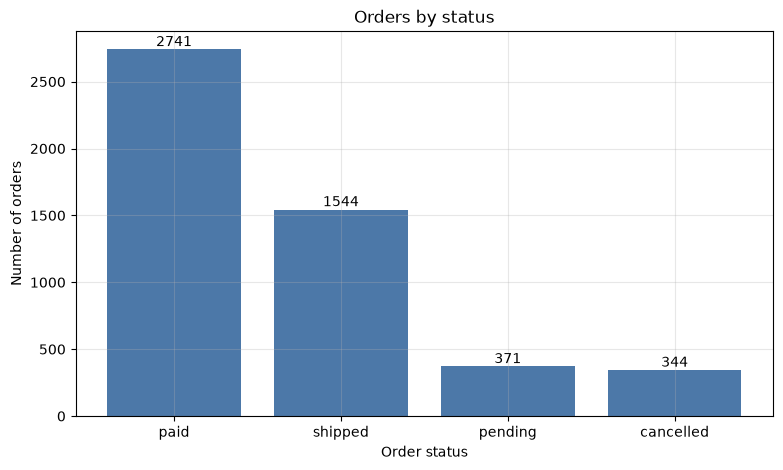

In [4]:
fig, ax = plt.subplots()
bars = ax.bar(status["status"], status["orders_count"], color="#4c78a8")
ax.bar_label(bars)
ax.set_title("Orders by status")
ax.set_xlabel("Order status")
ax.set_ylabel("Number of orders")
fig.savefig(FIG_DIR / "orders_by_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Monthly revenue and running total

Query `11_monthly_revenue_running.sql` (revenue = quantity x unit price, cancelled orders excluded).

In [5]:
monthly = query_df(read_query("11_monthly_revenue_running"))
monthly.head()

,month,revenue,running_total
0,2024-01,"152,655,500.00","152,655,500.00"
1,2024-02,"107,430,400.00","260,085,900.00"
2,2024-03,"119,831,900.00","379,917,800.00"
3,2024-04,"129,507,700.00","509,425,500.00"
4,2024-05,"124,208,800.00","633,634,300.00"


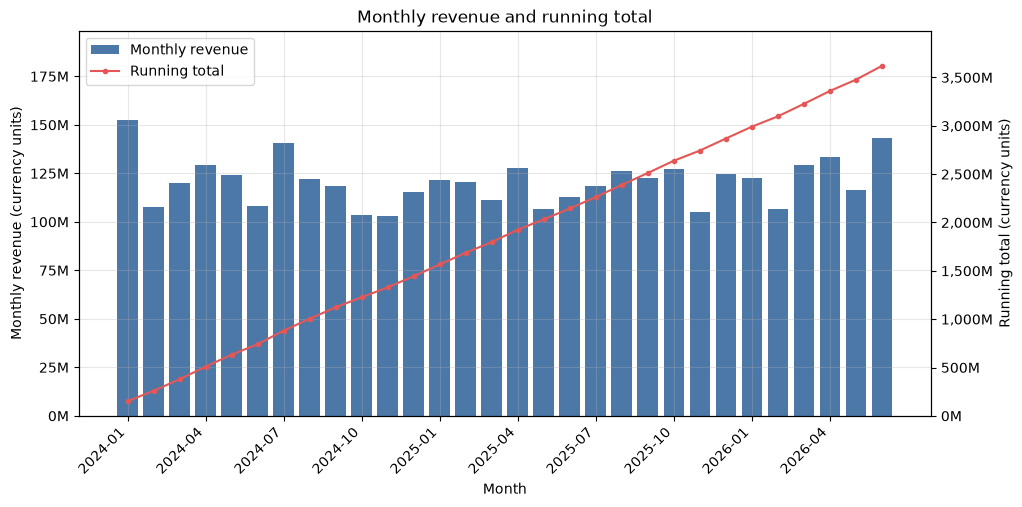

In [6]:
fig, ax_bars = plt.subplots(figsize=(11, 5))
positions = range(len(monthly))
ax_bars.bar(positions, monthly["revenue"], color="#4c78a8", label="Monthly revenue")
ax_bars.set_xlabel("Month")
ax_bars.set_ylabel("Monthly revenue (currency units)")
ax_bars.set_xticks(list(positions)[::3])
ax_bars.set_xticklabels(monthly["month"][::3], rotation=45, ha="right")
ax_bars.yaxis.set_major_formatter(millions)
ax_bars.set_ylim(0, monthly["revenue"].max() * 1.3)  
ax_line = ax_bars.twinx()
ax_line.plot(positions, monthly["running_total"], color="#e45756", marker="o", markersize=3, label="Running total")
ax_line.set_ylabel("Running total (currency units)")
ax_line.yaxis.set_major_formatter(millions)
ax_line.set_ylim(0, monthly["running_total"].max() * 1.1)
ax_line.grid(False)
handles = ax_bars.get_legend_handles_labels()[0] + ax_line.get_legend_handles_labels()[0]
labels = ax_bars.get_legend_handles_labels()[1] + ax_line.get_legend_handles_labels()[1]
ax_bars.legend(handles, labels, loc="upper left")
ax_bars.set_title("Monthly revenue and running total")
fig.savefig(FIG_DIR / "monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Revenue by category

Query `05_revenue_by_category.sql`. A book that belongs to several categories is counted in each of them, so the category totals add up to more than the real total revenue.

In [7]:
categories = query_df(read_query("05_revenue_by_category"))
top_categories = categories.head(10)
top_categories

,category,revenue
0,Fiction,"530,930,200.00"
1,Travel,"485,632,000.00"
2,Sports,"482,611,100.00"
3,Children,"422,131,900.00"
4,Nature,"411,067,600.00"
5,Self-Help,"391,309,500.00"
6,Music,"360,448,900.00"
7,Science Fiction,"323,016,200.00"
8,Biography,"322,516,500.00"
9,Mystery,"315,004,900.00"


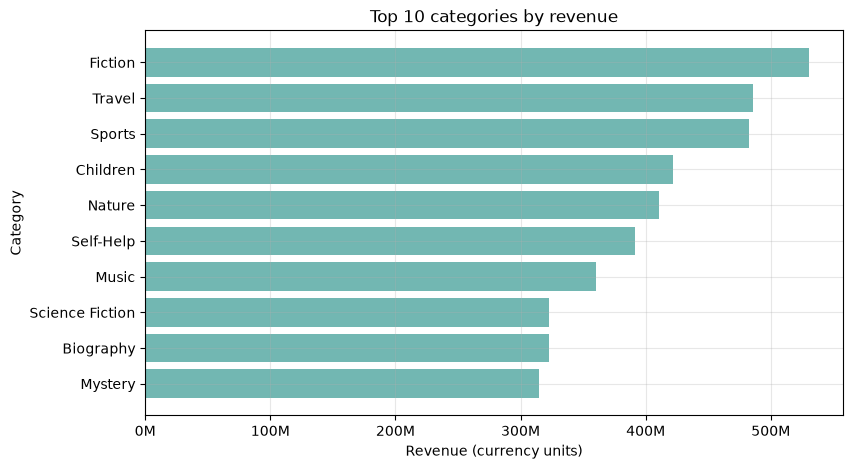

In [8]:
fig, ax = plt.subplots()
ax.barh(top_categories["category"][::-1], top_categories["revenue"][::-1], color="#72b7b2")
ax.set_title("Top 10 categories by revenue")
ax.xaxis.set_major_formatter(millions)
ax.set_xlabel("Revenue (currency units)")
ax.set_ylabel("Category")
fig.savefig(FIG_DIR / "revenue_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Rating distribution

In [9]:
ratings = query_df("SELECT rating FROM books WHERE rating IS NOT NULL")
total_books = query_df("SELECT COUNT(*) AS n FROM books")["n"].iloc[0]
missing_ratings = total_books - len(ratings)
print(f"{missing_ratings} of {total_books} books have no rating and are left out of the histogram.")

179 of 2000 books have no rating and are left out of the histogram.


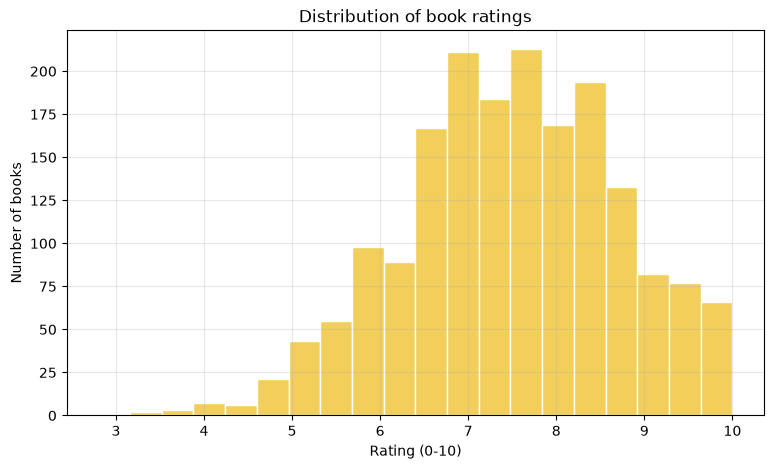

In [10]:
fig, ax = plt.subplots()
ax.hist(ratings["rating"], bins=20, color="#f2cf5b", edgecolor="white")
ax.set_title("Distribution of book ratings")
ax.set_xlabel("Rating (0-10)")
ax.set_ylabel("Number of books")
fig.savefig(FIG_DIR / "rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Top customers (parameterized query)

Uses the view `v_order_totals`.

In [11]:
TOP_N = 10
top_customers = query_df(
    """
    SELECT customer, COUNT(*) AS orders_count, SUM(total_amount) AS total_spent
    FROM v_order_totals
    WHERE status <> %s
    GROUP BY customer_id, customer
    ORDER BY total_spent DESC, customer_id
    LIMIT %s
    """,
    ("cancelled", TOP_N),
)
top_customers

,customer,orders_count,total_spent
0,Valerie Romero,10,"12,784,800.00"
1,Tiffany Phillips,9,"11,253,100.00"
2,William Mcpherson,10,"10,365,400.00"
3,Joel Allen,8,"9,903,300.00"
4,James Miller,13,"9,884,400.00"
5,Ashley Melendez,11,"9,407,700.00"
6,Robert Burgess,8,"9,228,400.00"
7,John Hamilton,8,"9,183,800.00"
8,Christine Burke,11,"9,162,300.00"
9,Jimmy Hawkins,10,"9,140,200.00"


## 7. Key findings

In [12]:
best_month = monthly.loc[monthly["revenue"].idxmax()]
cancelled_share = status.loc[status["status"] == "cancelled", "share_pct"].iloc[0]
total_revenue = monthly["running_total"].iloc[-1]
top_category = categories.iloc[0]
top_customer = top_customers.iloc[0]

print(f"Total revenue (cancelled orders excluded): {total_revenue:,.0f}")
print(f"Best month: {best_month['month']} with {best_month['revenue']:,.0f}")
print(f"Cancelled orders: {cancelled_share}% of all orders")
print(f"Top category by revenue: {top_category['category']} ({top_category['revenue']:,.0f})")
print(f"Top customer: {top_customer['customer']} spent {top_customer['total_spent']:,.0f} in {top_customer['orders_count']} orders")
print(f"Books without a rating: {missing_ratings} of {total_books}")

Total revenue (cancelled orders excluded): 3,620,195,600
Best month: 2024-01 with 152,655,500
Cancelled orders: 6.9% of all orders
Top category by revenue: Fiction (530,930,200)
Top customer: Valerie Romero spent 12,784,800 in 10 orders
Books without a rating: 179 of 2000


## Limitations

- The data is synthetic (generated with Faker and a fixed seed), so the numbers describe the generator, not a real shop.
- There is no currency in the schema; amounts are shown in "currency units".
- Category revenue counts a book once per category (see section 4).
- Ratings are random numbers between 0 and 10 and about 10% are missing on purpose.